<a href="https://colab.research.google.com/github/jjcodes999/flyrank-ml-repo/blob/main/work/notebooks/w07_action_playbook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ML-10 — Content Action Playbook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jjcodes999/flyrank-ml-repo/blob/main/work/notebooks/w07_action_playbook.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Ranked actions + reason codes

*The queue: what to do first, and why, in words a human trusts.*

Answer:

**What the queue is:** every page in my March 2026 frame (75,817 pages, 37 clients) is checked with my frozen Week-4 rule. 8,710 pages are flagged and ranked by their **estimated click gap** ("missed clicks" = impressions × the gap to the typical CTR of the page's position band, 1–15 March). The rule decides the order, because no learned model clearly beat it under the honest split (ML-08, ML-09). A random-forest probability, produced by a model that never saw the page's client, is added only as a **confidence** column.

**Actions and reason codes**

| Action | When | Pages | Est. click gap | Still below typical later |
|---|---|---|---|---|
| `check_data_quality` | average position below 1 (impossible) | 194 | 1,154 | 0.78 |
| `check_tracking_first` | 0 clicks in 1–15 March | 1,625 | 5,081 | 0.67 |
| `review_title_and_meta` | all other flagged pages | 6,891 | 25,938 | 0.67 |

Reason codes: `low_ctr_for_position` (every page in the queue), `zero_clicks`, `impossible_position`, and `dominant_client` (the page's client holds at least 20% of the top 100; 2 clients do). "Still below typical later" is observed afterwards, in 16–31 March, and is never used to rank.

The top of the queue shows why the extra codes matter: rank 1 is a data-quality case (position 0.11, 0 clicks from 83,772 impressions), rank 9 is a tracking case, and 13 of the top 15 come from the two dominant clients, so one site-level review may be more useful than many separate page edits.

**Archetype → action map** (rule-based types, not clusters; table below)

| Archetype | Pages | Est. click gap | Still below typical later | Action |
|---|---|---|---|---|
| A. Visible under-performer | 6,891 | 25,938 | 0.67 | review_title_and_meta |
| B. Silent page (0 clicks) | 1,625 | 5,081 | 0.67 | check_tracking_first |
| C. Broken position data | 194 | 1,154 | 0.78 | check_data_quality |
| D. Low CTR, low volume (<1,000 impressions) | 21,680 | 10,631 | 0.57 | monitor |
| E. Low CTR, deep position (>20) | 3,598 | 1,004 | 0.12 | out of scope for a CTR fix |
| F. At or above typical CTR | 41,829 | 0 | 0.20 | no action |

- **D** pages often stay below typical (0.57), but each carries a small gap (about 0.5 clicks on average), so they are watched rather than reviewed one by one.
- **E** pages rarely count as "still below" later (0.12), mostly because the typical CTR far down the results is close to 0. Their problem is ranking, not the snippet, so a title rewrite is the wrong tool.

**Decay insight (content age on 16 March 2026; table below)**

| Age | Pages | Below typical CTR | Flagged | Still below later |
|---|---|---|---|---|
| 0–90 days | 24,377 | 44% | 11.0% | 38% |
| 91–180 days | 14,333 | 46% | 12.3% | 37% |
| 181–270 days | 19,831 | 43% | 11.9% | 33% |
| 271–365 days | 9,575 | 44% | 10.2% | 32% |
| 365+ days | 7,701 | 49% | 12.0% | 36% |

In my lane, page age shows no clear "decay cliff": CTR problems appear at similar rates at every age (43–49% below typical, 10–12% flagged). The research paper's decay finding (health falling after about 270 days) is about a different outcome, its health score and impressions, so the two results do not contradict each other. For the playbook, age is not used to prioritise CTR reviews. I also cannot measure a **refresh** effect: `content_updated_date` only holds the latest update, which may be after March, so I cannot tell which pages were refreshed before the decision moment.

In [1]:
%pip -q install duckdb

import duckdb
import numpy as np
import pandas as pd
from google.colab import userdata

# Connect to the warehouse (token read from Colab's safe box)
HF_TOKEN = userdata.get("HF_TOKEN")
con = duckdb.connect()
con.execute(f"CREATE OR REPLACE SECRET hf (TYPE huggingface, TOKEN '{HF_TOKEN}')")
REL = "hf://datasets/FlyRank/internship-warehouse"
MARCH = f"read_parquet('{REL}/fact_content_daily_performance/month=2026-03/*.parquet')"

# Same frame as ML-04 to ML-09: one row per page. Clues 1-15 March, outcome 16-31 March.
pages = con.sql(f"""
    SELECT client_hash_id, content_hash_id,
        SUM(gsc_impressions) FILTER (WHERE report_date <= DATE '2026-03-15') AS impressions_h1,
        SUM(gsc_clicks)      FILTER (WHERE report_date <= DATE '2026-03-15') AS clicks_h1,
        SUM(gsc_avg_position * gsc_impressions) FILTER (WHERE report_date <= DATE '2026-03-15' AND gsc_avg_position > 0)
          / NULLIF(SUM(gsc_impressions) FILTER (WHERE report_date <= DATE '2026-03-15' AND gsc_avg_position > 0), 0) AS position_h1,
        COUNT(DISTINCT report_date) FILTER (WHERE report_date <= DATE '2026-03-15' AND gsc_impressions > 0) AS days_visible_h1,
        SUM(gsc_impressions) FILTER (WHERE report_date > DATE '2026-03-15') AS impressions_h2,
        SUM(gsc_clicks)      FILTER (WHERE report_date > DATE '2026-03-15') AS clicks_h2,
        SUM(gsc_avg_position * gsc_impressions) FILTER (WHERE report_date > DATE '2026-03-15' AND gsc_avg_position > 0)
          / NULLIF(SUM(gsc_impressions) FILTER (WHERE report_date > DATE '2026-03-15' AND gsc_avg_position > 0), 0) AS position_h2
    FROM {MARCH}
    WHERE gsc_data_available IS TRUE
    GROUP BY client_hash_id, content_hash_id
    HAVING impressions_h1 >= 100 AND impressions_h2 >= 50
""").df()
pages = pages.dropna(subset=["position_h1", "position_h2"]).copy()
pages = pages.sort_values(["client_hash_id", "content_hash_id"]).reset_index(drop=True)  # fixed order -> reproducible

bands = [0, 3, 5, 7, 10, 15, 20, 30, 50, 1000]
pages["ctr_h1"] = pages["clicks_h1"] / pages["impressions_h1"] * 100
pages["band_h1"] = pd.cut(pages["position_h1"], bands)
pages["expected_ctr_h1"] = pages.groupby("band_h1", observed=True)["ctr_h1"].transform("median")
pages["missed_clicks_h1"] = pages["impressions_h1"] * (pages["expected_ctr_h1"] - pages["ctr_h1"]) / 100

# Outcome (16-31 March) - used ONLY to check the playbook, never to rank
pages["ctr_h2"] = pages["clicks_h2"] / pages["impressions_h2"] * 100
pages["band_h2"] = pd.cut(pages["position_h2"], bands)
pages["expected_ctr_h2"] = pages.groupby("band_h2", observed=True)["ctr_h2"].transform("median")
pages["still_under"] = (pages["ctr_h2"] < pages["expected_ctr_h2"]).astype(int)

# The frozen Week-4 rule decides WHO is in the queue and IN WHAT ORDER
MIN_IMPRESSIONS, MAX_POSITION = 1000, 20
flagged = (pages["impressions_h1"] >= MIN_IMPRESSIONS) & (pages["position_h1"] <= MAX_POSITION) & (pages["ctr_h1"] < pages["expected_ctr_h1"])
pages["flagged"] = flagged
pages["score"] = np.where(flagged, pages["missed_clicks_h1"], 0.0)
FEATURES = ["impressions_h1", "ctr_h1", "position_h1", "days_visible_h1", "missed_clicks_h1"]

# Second opinion: random-forest probability that the problem lasts, scored by a model that never saw the page's client
from sklearn.model_selection import GroupKFold
from sklearn.ensemble import RandomForestClassifier
folds = list(GroupKFold(n_splits=5).split(pages, groups=pages["client_hash_id"]))
pages["persistence_prob"] = np.nan
for train_idx, test_idx in folds:
    train, test = pages.iloc[train_idx], pages.iloc[test_idx]
    rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=20, random_state=42, n_jobs=-1)
    rf.fit(train[FEATURES], train["still_under"])
    pages.loc[test.index, "persistence_prob"] = rf.predict_proba(test[FEATURES])[:, 1]
pages["confidence"] = pd.cut(pages["persistence_prob"], [-0.01, 0.6, 0.8, 1.0], labels=["low", "medium", "high"]).astype(str)

# The queue: flagged pages, biggest estimated click gap first
queue = pages[pages["flagged"]].sort_values("score", ascending=False).reset_index(drop=True)
queue["rank"] = queue.index + 1
top100_share = queue.head(100)["client_hash_id"].value_counts() / 100
dominant_clients = set(top100_share[top100_share >= 0.20].index)

# Action: data problems first, then tracking, otherwise a title/meta review
queue["action"] = np.select(
    [queue["position_h1"] < 1, queue["clicks_h1"] == 0],
    ["check_data_quality", "check_tracking_first"],
    default="review_title_and_meta")

def reason_codes(row):
    codes = ["low_ctr_for_position"]
    if row["clicks_h1"] == 0: codes.append("zero_clicks")
    if row["position_h1"] < 1: codes.append("impossible_position")
    if row["client_hash_id"] in dominant_clients: codes.append("dominant_client")
    return "; ".join(codes)
queue["reason_codes"] = queue.apply(reason_codes, axis=1)
queue["client"] = queue["client_hash_id"].str[-6:]

print(f"Pages scored: {len(pages):,} | flagged into the queue: {len(queue):,} | clients: {pages['client_hash_id'].nunique()}")
print("Clients holding at least 20% of the top 100:", len(dominant_clients))
print("\nQueue by action (still_under_rate = share still below typical CTR in 16-31 March, observed afterwards):")
display(queue.groupby("action").agg(pages=("rank", "size"), missed_clicks=("score", "sum"),
                                    still_under_rate=("still_under", "mean")).round(2))
show = ["rank", "client", "impressions_h1", "clicks_h1", "ctr_h1", "expected_ctr_h1", "position_h1",
        "score", "action", "reason_codes", "confidence"]
print("\nTop 15 of the queue:")
display(queue[show].head(15).round(2))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Pages scored: 75,817 | flagged into the queue: 8,710 | clients: 37
Clients holding at least 20% of the top 100: 2

Queue by action (still_under_rate = share still below typical CTR in 16-31 March, observed afterwards):


,pages,missed_clicks,still_under_rate
action,,,
check_data_quality,194,1154.49,0.78
check_tracking_first,1625,5081.30,0.67
review_title_and_meta,6891,25938.07,0.67



Top 15 of the queue:


,rank,client,impressions_h1,clicks_h1,ctr_h1,expected_ctr_h1,position_h1,score,action,reason_codes,confidence
0,1,f265ea,83772.0,0.0,0.00,0.25,0.11,205.68,check_data_quality,low_ctr_for_position; zero_clicks; impossible_...,high
1,2,5e0096,73639.0,18.0,0.02,0.25,2.95,162.80,review_title_and_meta,low_ctr_for_position; dominant_client,high
2,3,f265ea,58553.0,1.0,0.00,0.24,4.75,142.19,review_title_and_meta,low_ctr_for_position; dominant_client,high
3,4,5e0096,52378.0,18.0,0.03,0.24,4.65,110.09,review_title_and_meta,low_ctr_for_position; dominant_client,high
4,5,5e0096,86860.0,51.0,0.06,0.17,5.95,93.17,review_title_and_meta,low_ctr_for_position; dominant_client,high
5,6,9f63c4,55680.0,15.0,0.03,0.17,6.68,77.41,review_title_and_meta,low_ctr_for_position,high
6,7,5e0096,83715.0,133.0,0.16,0.24,3.52,71.72,review_title_and_meta,low_ctr_for_position; dominant_client,high
7,8,5e0096,49314.0,2.0,0.00,0.14,8.42,67.95,review_title_and_meta,low_ctr_for_position; dominant_client,high
8,9,5e0096,27715.0,0.0,0.00,0.24,4.45,67.77,check_tracking_first,low_ctr_for_position; zero_clicks; dominant_cl...,high
9,10,043229,33020.0,14.0,0.04,0.25,1.60,67.07,review_title_and_meta,low_ctr_for_position,high


In [2]:
# ARCHETYPE -> ACTION: every page sorted into one simple type (rule-based types, not clusters)
below = pages["ctr_h1"] < pages["expected_ctr_h1"]
pages["archetype"] = np.select(
    [pages["flagged"] & (pages["position_h1"] < 1),
     pages["flagged"] & (pages["clicks_h1"] == 0),
     pages["flagged"],
     below & (pages["position_h1"] > MAX_POSITION),
     below],
    ["C. Broken position data", "B. Silent page (0 clicks)", "A. Visible under-performer",
     "E. Low CTR, deep position (>20)", "D. Low CTR, low volume (<1,000 impr.)"],
    default="F. At or above typical CTR")

action_for = {
    "A. Visible under-performer": "review_title_and_meta",
    "B. Silent page (0 clicks)": "check_tracking_first",
    "C. Broken position data": "check_data_quality",
    "D. Low CTR, low volume (<1,000 impr.)": "monitor",
    "E. Low CTR, deep position (>20)": "out_of_scope_for_ctr_fix",
    "F. At or above typical CTR": "no_action",
}
arche = pages.groupby("archetype").agg(
    pages=("still_under", "size"),
    missed_clicks=("missed_clicks_h1", lambda s: s.clip(lower=0).sum()),
    still_under_rate=("still_under", "mean")).round(2)
arche.insert(0, "action", [action_for[a] for a in arche.index])
display(arche)

,action,pages,missed_clicks,still_under_rate
archetype,,,,
A. Visible under-performer,review_title_and_meta,6891,25938.07,0.67
B. Silent page (0 clicks),check_tracking_first,1625,5081.30,0.67
C. Broken position data,check_data_quality,194,1154.49,0.78
"D. Low CTR, low volume (<1,000 impr.)",monitor,21680,10630.68,0.57
"E. Low CTR, deep position (>20)",out_of_scope_for_ctr_fix,3598,1004.24,0.12
F. At or above typical CTR,no_action,41829,0.00,0.20


In [3]:
# DECAY INSIGHT: content age at the decision moment (16 March 2026) vs CTR problems
CONTENT = f"read_parquet('{REL}/dim_content.parquet')"
created = con.sql(f"SELECT client_hash_id, content_hash_id, content_created_date FROM {CONTENT}").df()
aged = pages.merge(created, on=["client_hash_id", "content_hash_id"], how="left")
aged["age_days"] = (pd.Timestamp("2026-03-16") - pd.to_datetime(aged["content_created_date"])).dt.days
aged = aged[aged["age_days"] >= 0]
aged["age_bucket"] = pd.cut(aged["age_days"], [-1, 90, 180, 270, 365, 100000],
                            labels=["0-90 d", "91-180 d", "181-270 d", "271-365 d", "365+ d"])
decay = aged.groupby("age_bucket", observed=True).agg(
    pages=("still_under", "size"),
    share_below_typical_ctr=("ctr_h1", lambda s: (s < aged.loc[s.index, "expected_ctr_h1"]).mean()),
    share_flagged=("flagged", "mean"),
    still_under_rate=("still_under", "mean")).round(3)
print("Pages with a known creation date:", len(aged), "of", len(pages))
display(decay)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Pages with a known creation date: 75817 of 75817


,pages,share_below_typical_ctr,share_flagged,still_under_rate
age_bucket,,,,
0-90 d,24377,0.442,0.110,0.382
91-180 d,14333,0.464,0.123,0.367
181-270 d,19831,0.430,0.119,0.325
271-365 d,9575,0.444,0.102,0.321
365+ d,7701,0.493,0.120,0.361


## 2. Intended use and limits

*Who uses this, for what — and where it stops being valid.*

Answer:

**Who uses it and for what:** an SEO or content editor deciding which pages to review first for a click-through problem. The queue is decision-support: it says where to look, not what to change, and every action needs a person (Section 3).

**How often:** once a month, on the latest complete month, following the same recipe (first half of the month → ranking; second half → check).

**What the evidence supports** (5 client-grouped folds; table below):

| | P@10 | P@20 | P@50 | P@100 |
|---|---|---|---|---|
| Random pick (base rate) | 0.35 | 0.35 | 0.35 | 0.35 |
| Rule (the queue) | 0.94 | 0.93 | 0.92 | 0.90 |
| Random forest (confidence column) | 0.98 | 0.98 | 0.92 | 0.88 |

In words: of the top 20 pages per fold, about 93% were still below typical CTR for their position two weeks later, against 35% for a random pick. The rule's numbers are slightly optimistic, because its 1,000-impression cutoff was chosen on the same month (ML-09).

**Cost / value thinking** ("click gap" = estimated missed clicks in 1–15 March, not a promised gain; table below):

| Pages reviewed | Click gap covered | Share of the queue's total gap | Gap per page in that slice |
|---|---|---|---|
| Top 20 | 1,619 | 5.0% | ~81 |
| Top 50 | 2,822 | 8.8% | ~40 (ranks 21–50) |
| Top 100 | 4,246 | 13.2% | ~28 (ranks 51–100) |
| Top 500 | 10,504 | 32.6% | ~16 (ranks 101–500) |
| Top 1,000 | 14,878 | 46.2% | ~9 (ranks 501–1,000) |
| All 8,710 | 32,174 | 100% | ~2 (ranks 1,001+) |

- Value falls fast down the list: a page in the top 20 carries about 9 times the click gap of a page ranked 501–1,000.
- **Cost assumption (not measured):** if a careful title/meta review takes about 20 minutes, the top 20 is roughly 7 editor-hours. Reviewing all 8,710 pages (about 2,900 hours) would not be worth it.
- **Cost of errors:** a false alarm wastes one review (about 7 of every 100 top picks were not still below typical later). Misses are rare at the top of the list and common deeper down, but most missed pages carry small gaps (archetype D: about 0.5 clicks each).
- **Recommended capacity:** clear the data-quality and tracking checks first, then review about 20–50 pages per cycle, starting at the top.

**Limits: where it stops being valid**
- One month of data (March 2026): features from 1–15 March, outcome from 16–31 March. Not tested on other months or seasons.
- Only pages with `gsc_data_available IS TRUE`, at least 100 impressions in the first half and 50 in the second: 75,817 pages from 37 clients, about 23% of March's pages. It says nothing about quieter pages or other clients.
- Two clients make up 72% of the queue (6,266 of 8,710 pages), so the results are heavily shaped by them.
- "Still below typical" is a proxy. Nothing here shows that editing a page will raise its clicks; that would need an experiment (for example, edit half of the top pages and compare them with the other half).
- Position is an average over many searches; a page's main search could rank very differently.

In [4]:
# WHAT THE EVIDENCE SUPPORTS (honest grouped split) + COST/VALUE
def precision_at_k(scores, labels, k):
    order = np.argsort(-np.asarray(scores), kind="stable")
    return np.asarray(labels)[order[:k]].mean()

KS = [10, 20, 50, 100]
rows = []
for i, (train_idx, test_idx) in enumerate(folds, 1):
    test = pages.iloc[test_idx]; y = test["still_under"].values
    rows.append({"method": "Random pick (base rate)", **{f"P@{k}": y.mean() for k in KS}})
    rows.append({"method": "Rule (the queue)", **{f"P@{k}": precision_at_k(test["score"].values, y, k) for k in KS}})
    rows.append({"method": "Random forest (confidence column)", **{f"P@{k}": precision_at_k(test["persistence_prob"].values, y, k) for k in KS}})
pk = pd.DataFrame(rows).groupby("method", sort=False).mean().round(3)
print("Precision@K on clients never used for training, averaged over 5 client-grouped folds:")
display(pk)

total_gap = queue["score"].sum()
capture = pd.DataFrame({"pages_reviewed": sorted({n for n in [20, 50, 100, 500, 1000] if n < len(queue)} | {len(queue)})})
capture["missed_clicks_covered"] = [queue["score"].head(n).sum() for n in capture["pages_reviewed"]]
capture["share_of_queue_gap"] = (capture["missed_clicks_covered"] / total_gap).round(3)
capture["missed_clicks_covered"] = capture["missed_clicks_covered"].round(0)
print("\nCost/value: estimated click gap covered by reviewing the top N of the queue (1-15 March):")
display(capture)

Precision@K on clients never used for training, averaged over 5 client-grouped folds:


,P@10,P@20,P@50,P@100
method,,,,
Random pick (base rate),0.351,0.351,0.351,0.351
Rule (the queue),0.940,0.930,0.924,0.898
Random forest (confidence column),0.980,0.980,0.920,0.884



Cost/value: estimated click gap covered by reviewing the top N of the queue (1-15 March):


,pages_reviewed,missed_clicks_covered,share_of_queue_gap
0,20,1619.0,0.050
1,50,2822.0,0.088
2,100,4246.0,0.132
3,500,10504.0,0.326
4,1000,14878.0,0.462
5,8710,32174.0,1.000


## 3. Human review + the no-go list

*What a person must check before acting. What should never be automated.*

Answer:

**Before acting on any page, a person checks** (counts from the current queue below):
1. **Is the data real?** 194 pages have an average position below 1. Treat them as data errors; do not edit.
2. **Is tracking working?** 1,676 pages had 0 clicks in 1–15 March. Confirm that clicks are being recorded and the page is indexed before rewriting anything.
3. **Is this one site's pattern?** 6,266 pages (72% of the queue) come from two clients that each hold at least 20% of the top 100. Look at the site as a whole first (page templates, brand searches, search features) before editing pages one by one.
4. **How confident is the second opinion?** 2,836 pages are "low" confidence (forest probability below 0.6). Put them later in the review order.
5. **Look at the real search result:** what the page actually shows for its main searches (title, description, any answer box or ads above it), and whether the page matches what people are looking for.
6. **Record the decision** (edit / no edit / why), so the next cycle can compare.

**The no-go list: never automate these**
- Rewriting or publishing titles or meta descriptions automatically.
- Deleting, merging, redirecting or de-indexing pages based on the queue.
- Acting on pages flagged `check_data_quality` or `check_tracking_first` before the check is done.
- Using the queue for pages outside its population (fewer than 100 impressions, no search data, other months) or for clients not in the data.
- Judging editors, writers or clients by their pages' scores.
- Promising or reporting click gains from the click gap. It is an estimate of a gap, not a forecast.
- Re-tuning the rule on the same month and then reporting its precision as if it were a fresh test.

In [5]:
# WHAT A REVIEWER MUST CHECK - counts in the current queue
checks = {
    "Pages in the queue": len(queue),
    "0 clicks in 1-15 March (check tracking before any edit)": int((queue["clicks_h1"] == 0).sum()),
    "Average position below 1 (data error - do not act)": int((queue["position_h1"] < 1).sum()),
    "From a client holding >=20% of the top 100 (consider one site-level review)": int(queue["reason_codes"].str.contains("dominant_client").sum()),
    "Low confidence (forest probability < 0.6)": int((queue["confidence"] == "low").sum()),
}
display(pd.Series(checks, name="pages").to_frame())

,pages
Pages in the queue,8710
0 clicks in 1-15 March (check tracking before any edit),1676
Average position below 1 (data error - do not act),194
From a client holding >=20% of the top 100 (consider one site-level review),6266
Low confidence (forest probability < 0.6),2836


## 4. Monitoring / retrain triggers

*What would tell you the recommendations went stale?*

Answer:

The queue is rebuilt each month. These are the warning signs that it has gone stale and the rule (or the forest) needs to be re-checked or re-tuned. The March 2026 values are computed in the code below.

| What I watch | March 2026 | Trigger |
|---|---|---|
| Base rate (share still under-performing) | 0.35 | moves by more than 0.10 |
| Rule Precision@20 (client-grouped folds) | 0.93 | falls below 0.80 on a new month |
| Pages flagged into the queue | 8,710 | changes by more than 30% |
| Share of the queue with 0 clicks | 0.19 | rises above 0.25 (possible tracking problem) |
| Pages with position below 1 | 194 | any increase (data problem) |
| Largest client's share of the top 50 | 0.44 | rises above 0.60 |
| Clients in the frame | 37 | any client added or dropped |

**Also re-check when:** Google changes how results look (new answer boxes or AI summaries can lower CTR for every page at once); the share of rows with `gsc_data_available` TRUE changes a lot (36.7% in March, ML-04); or reviewers report that many flagged pages turned out to be fine.

**What "retrain" means here:** first re-run the ML-07 signal checks and re-pick the impressions cutoff on an earlier month, then test on the following month (a time split). Only bring the random forest into the ranking if it beats the rule on that later month at the capacity editors actually use (top 20–50), on both precision and click gap covered. This is a monthly notebook routine, not a production system.

In [6]:
# REFERENCE VALUES to compare against next month
top50 = queue.head(50)
reference = pd.DataFrame([
    ("Base rate (share still under-performing)", round(pages["still_under"].mean(), 3), "moves by more than 0.10"),
    ("Rule Precision@20 (grouped folds)", float(pk.loc["Rule (the queue)", "P@20"]), "falls below 0.80 on a new month"),
    ("Pages flagged into the queue", len(queue), "changes by more than 30%"),
    ("Share of queue with 0 clicks", round((queue["clicks_h1"] == 0).mean(), 3), "rises above 0.25"),
    ("Pages with position below 1 in the queue", int((queue["position_h1"] < 1).sum()), "any increase"),
    ("Largest client's share of the top 50", round(top50["client_hash_id"].value_counts().iloc[0] / 50, 2), "rises above 0.60"),
    ("Clients in the frame", pages["client_hash_id"].nunique(), "any client added or dropped"),
], columns=["what I watch", "March 2026 value", "re-check / retrain trigger"])
display(reference)

,what I watch,March 2026 value,re-check / retrain trigger
0,Base rate (share still under-performing),0.355,moves by more than 0.10
1,Rule Precision@20 (grouped folds),0.930,falls below 0.80 on a new month
2,Pages flagged into the queue,8710.000,changes by more than 30%
3,Share of queue with 0 clicks,0.192,rises above 0.25
4,Pages with position below 1 in the queue,194.000,any increase
5,Largest client's share of the top 50,0.440,rises above 0.60
6,Clients in the frame,37.000,any client added or dropped


## 5. Exports for the paper

*Write the queue (and any figures you want to reuse) to work/outputs/ — your paper builds on these files.*

Answer:

The code below writes the files my paper will build on:

| File | What it is | In git? |
|---|---|---|
| `work/outputs/ctr_action_queue.csv` | the full ranked queue (8,710 pages): rank, scrambled IDs, first-half numbers, click gap, action, reason codes, confidence. No outcome column. | No. Data files stay out of git by design; the notebook regenerates it on every run. |
| `work/outputs/playbook_metrics.json` | the receipts: data window, counts, Precision@K table, queue by action, click-gap coverage, archetypes, age table, seeds and folds | Yes |
| `work/figures/precision_at_k.png` | Precision@K on unseen clients: rule vs forest vs random pick | Yes |
| `work/figures/click_gap_coverage.png` | share of the queue's estimated click gap covered as more pages are reviewed | Yes |

Everything is computed in this notebook from the March 2026 warehouse partition with fixed seeds (`random_state=42`, `GroupKFold(5)` by client), so re-running it reproduces the same files. This is a notebook routine for a monthly review, not a production pipeline.

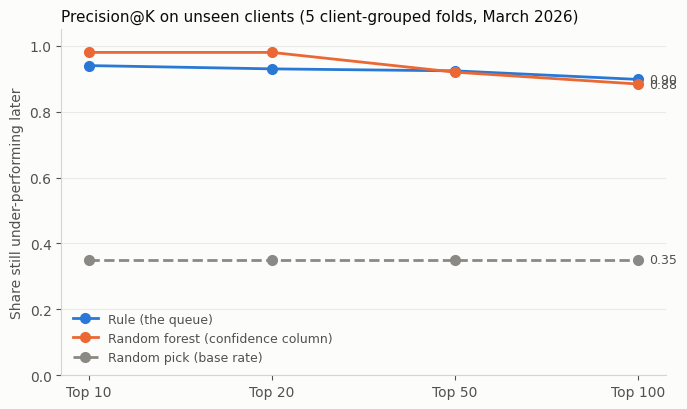

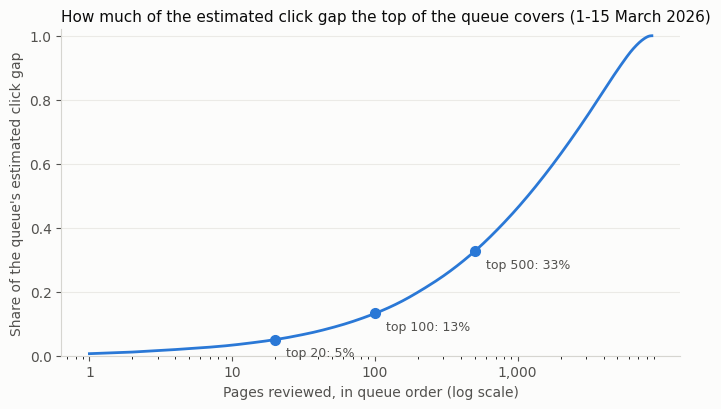

work/outputs/ctr_action_queue.csv: 1,925,433 bytes
work/outputs/playbook_metrics.json: 2,865 bytes
work/figures/precision_at_k.png: 60,049 bytes
work/figures/click_gap_coverage.png: 66,463 bytes


In [7]:
# EXPORTS FOR THE PAPER
import os, json
import matplotlib.pyplot as plt
os.makedirs("work/outputs", exist_ok=True)
os.makedirs("work/figures", exist_ok=True)

# 1) The ranked queue (stays out of git; no outcome column inside)
queue_cols = ["rank", "client_hash_id", "content_hash_id", "impressions_h1", "clicks_h1", "ctr_h1",
              "position_h1", "expected_ctr_h1", "score", "action", "reason_codes", "persistence_prob", "confidence"]
queue[queue_cols].to_csv("work/outputs/ctr_action_queue.csv", index=False)

# 2) The receipts: every key number in one file
metrics = {
    "data": "FlyRank warehouse, month=2026-03; features 1-15 March, outcome 16-31 March",
    "pages_scored": int(len(pages)), "clients": int(pages["client_hash_id"].nunique()),
    "pages_in_queue": int(len(queue)),
    "base_rate": round(float(pages["still_under"].mean()), 3),
    "precision_at_k_grouped_5fold": {m: {k: float(v) for k, v in r.items()} for m, r in pk.to_dict("index").items()},
    "queue_by_action": {k: int(v) for k, v in queue["action"].value_counts().items()},
    "missed_clicks_covered": {str(int(r.pages_reviewed)): {"missed_clicks": float(r.missed_clicks_covered), "share": float(r.share_of_queue_gap)}
                              for r in capture.itertuples()},
    "archetypes": {a: {"pages": int(r.pages), "action": r.action, "still_under_rate": float(r.still_under_rate)} for a, r in arche.iterrows()},
    "decay_by_age": {str(b): {k: float(v) for k, v in r.items()} for b, r in decay.iterrows()},
    "seeds": {"random_forest": 42}, "folds": "GroupKFold(5) by client_hash_id",
}
with open("work/outputs/playbook_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

# 3) Two figures (one axis each, colour-blind-safe blue/orange, grey for the random baseline)
BLUE, ORANGE, GRAY, INK, INK2, SURFACE = "#2a78d6", "#eb6834", "#8a8984", "#0b0b0b", "#52514e", "#fcfcfb"
def style(ax):
    ax.set_facecolor(SURFACE)
    for s in ["top", "right"]: ax.spines[s].set_visible(False)
    for s in ["left", "bottom"]: ax.spines[s].set_color("#d6d5d0")
    ax.tick_params(colors=INK2); ax.grid(axis="y", color="#ebeae6", linewidth=0.8); ax.set_axisbelow(True)

# Figure 1: Precision@K - rule vs forest vs random pick
fig, ax = plt.subplots(figsize=(7, 4.2), facecolor=SURFACE); style(ax)
x = list(range(len(KS)))
for name, color, ls in [("Rule (the queue)", BLUE, "-"), ("Random forest (confidence column)", ORANGE, "-"), ("Random pick (base rate)", GRAY, "--")]:
    vals = [pk.loc[name, f"P@{k}"] for k in KS]
    ax.plot(x, vals, ls, color=color, linewidth=2, marker="o", markersize=7, label=name)
    ax.annotate(f"{vals[-1]:.2f}", (x[-1], vals[-1]), xytext=(8, 0), textcoords="offset points", va="center", color=INK2, fontsize=9)
ax.set_xticks(x, [f"Top {k}" for k in KS]); ax.set_ylim(0, 1.05); ax.set_ylabel("Share still under-performing later", color=INK2)
ax.set_title("Precision@K on unseen clients (5 client-grouped folds, March 2026)", color=INK, fontsize=11, loc="left")
ax.legend(frameon=False, loc="lower left", fontsize=9, labelcolor=INK2)
fig.tight_layout(); fig.savefig("work/figures/precision_at_k.png", dpi=150); plt.show()

# Figure 2: estimated click gap covered as more pages are reviewed
cum = queue["score"].cumsum() / total_gap
fig, ax = plt.subplots(figsize=(7, 4.2), facecolor=SURFACE); style(ax)
ax.plot(queue["rank"], cum, color=BLUE, linewidth=2)
for n in [20, 100, 500]:
    if n <= len(queue):
        ax.plot(n, cum.iloc[n - 1], "o", color=BLUE, markersize=7)
        ax.annotate(f"top {n}: {cum.iloc[n - 1]:.0%}", (n, cum.iloc[n - 1]), xytext=(8, -12), textcoords="offset points", color=INK2, fontsize=9)
ax.set_xscale("log"); ax.set_ylim(0, 1.02)
ticks = [t for t in [1, 10, 100, 1000, 10000] if t <= len(queue)]
ax.set_xticks(ticks, [f"{t:,}" for t in ticks])
ax.set_xlabel("Pages reviewed, in queue order (log scale)", color=INK2); ax.set_ylabel("Share of the queue's estimated click gap", color=INK2)
ax.set_title("How much of the estimated click gap the top of the queue covers (1-15 March 2026)", color=INK, fontsize=11, loc="left")
fig.tight_layout(); fig.savefig("work/figures/click_gap_coverage.png", dpi=150); plt.show()

for p in ["work/outputs/ctr_action_queue.csv", "work/outputs/playbook_metrics.json",
          "work/figures/precision_at_k.png", "work/figures/click_gap_coverage.png"]:
    print(f"{p}: {os.path.getsize(p):,} bytes")

## Self-check

Before you submit, confirm each line honestly:

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [x] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.